<a href="https://colab.research.google.com/github/nbulotti/2026_ML_EES/blob/main/live/part-II/3.3-decision-trees-and-random-forest-exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-II/3.3-decision-trees-and-random-forest-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

# 3.3) (Exercises) Decision Trees and Random Forest

Now we move to creating and training decision trees. Here we will learn how to train and fine-tune a decision tree on a synthetic dataset.

Since decision trees contain multiple trainable hyperparameters, parts of this notebook focus on adjusting and optimizing multiple hyperparameters in the decision tree algorithm.

**🎯 Learning objectives**

- Train a decision tree
- Tune hyperparameters with cross-validation
- Compute the classification accuracy of the tuned model and visualise its errors
- Replace the decision tree with a random forest and compare the accuracy

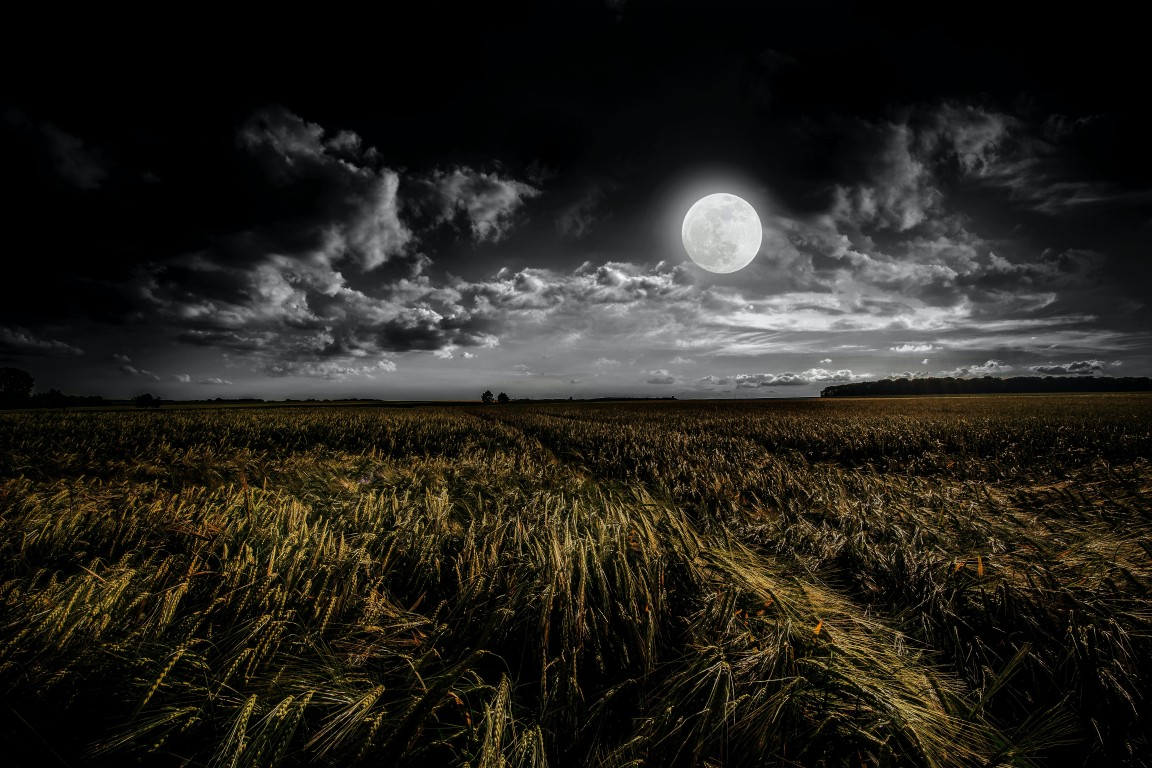

Can we grow a tree to predict the moon? 🌳 🌛

The goal of this exercise is to train and adjust the hyperparameters of a decision tree on a synthetic "moons" dataset. The dataset contains two interleaving half circles that we seek to separate via classification.

First, let's generate a moons dataset using [`make_moons`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html).

In [1]:
from sklearn.datasets import make_moons # Import function to make moons

In [2]:
# Make 10,000 samples with Gaussian noise that has a standard deviation of 0.4
X, y = make_moons(n_samples=10000, noise=0.4)

**Q1) Split the moons dataset into a training and a test set**

Hint 1: You may use the [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) function of `scikit-learn`.

Hint 2: Here we will keep 20% of the dataset for testing.

Hint 3: To ensure you get the same result every time you run the code, we will specify the `random_state` option in `train_test_split` function to be 42.

In [3]:
# Import the train_test_split function here.
from sklearn.model_selection import train_test_split

# Split the dataset into a training set and a test set
# There will be four outputs in this function. 2 for X (train and test) and 2 for y (train and test)
# test_size=0.2 --> 20% of the 10,000 points kept for testing (2,000) | random_state=42 --> same split every run
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**Q2) Visualize the data, indicating which points belong to each half circle of the moon, and which points belong to the training and test sets**

Hint 1: In the moons dataset, `X` contains the 2D spatial coordinates of each sample, while `y` indicates which half circle of the moon the sample belongs to.

Hint 2: You may randomly subsample your data for visualization purposes. Alternatively, you can adjust the size and transparency of a [Matplotlib scatter plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) by varying the parameters `s` and `alpha`. We adopt the latter visualization method in the code snippet. Do not hesitate to experiment with the first visualization method as long as the figure looks good.

(Q2)=

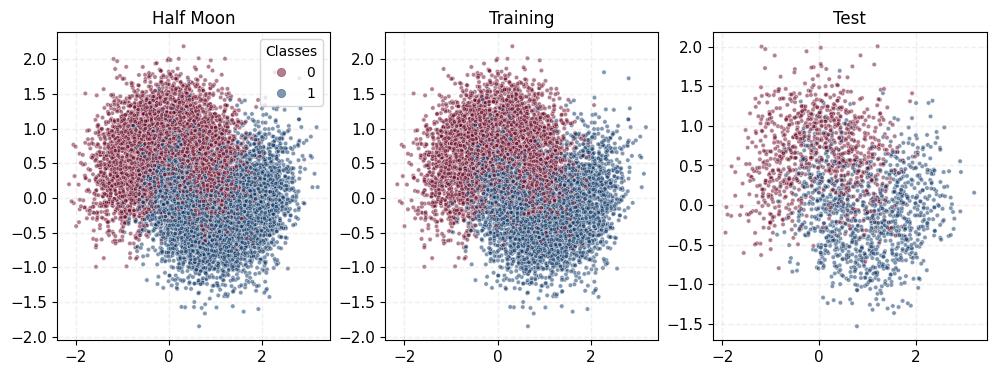

In [4]:
# Scatter the moon data and don't forget to add a legend to your figure
import numpy as np
import matplotlib.pyplot as plt
# (1,3) --> 1 row, 3 plots side by side | ax is now an ARRAY of 3 plots --> ax[0], ax[1], ax[2]
fig,ax = plt.subplots(1,3,figsize=(12,4))
#########################################################################################################
# (1) Plot the whole dataset with plt.scatter
#########################################################################################################
# The X and y indices of each data point can be obtained like this: X[:,0], X[:,1]
# The scatter points should be coloured by y
# c=y --> color depends on the class (0 or 1) | cmap='RdBu' --> class 0 red, class 1 blue
# small s + alpha=0.5 --> 10,000 points without one big blob
scatter = ax[0].scatter(X[:,0],X[:,1],s=10,c=y,edgecolor='w',linewidths=0.5,alpha=0.5,cmap='RdBu')
# Add legend to the upper right corner of the figure
# legend_elements() --> builds one legend entry per class automatically from the colors
legend1 = ax[0].legend(*scatter.legend_elements(),loc='upper right', title="Classes")
ax[0].set_title('Half Moon')
ax[0].tick_params(axis='both', which='major', labelsize=11)
ax[0].grid(alpha=0.2,ls='--',lw=1)

#########################################################################################################
# (2) Plot the training dataset with plt.scatter
#########################################################################################################
# same thing but only the 80% training points --> colored by y_train
scatter_train = ax[1].scatter(X_train[:,0],X_train[:,1],s=10,c=y_train,edgecolor='w',linewidths=0.5,alpha=0.5,cmap='RdBu')
ax[1].set_title('Training')
ax[1].tick_params(axis='both', which='major', labelsize=11)
ax[1].grid(alpha=0.2,ls='--',lw=1)

#########################################################################################################
# (2) Plot the test dataset with plt.scatter
#########################################################################################################
# the remaining 20% --> colored by y_test
scatter_test = ax[2].scatter(X_test[:,0],X_test[:,1],s=10,c=y_test,edgecolor='w',linewidths=0.5,alpha=0.5,cmap='RdBu')
ax[2].set_title('Test')
ax[2].tick_params(axis='both', which='major', labelsize=11)
ax[2].grid(alpha=0.2,ls='--',lw=1)

plt.show()

Do your data & training/test splits look reasonable?

**Q3) Conduct a hyperparameter search to find the two hyperparameters that lead to the best-performing decision tree**

Hint 1: You can conduct an exhaustive hyperparameter search over specified parameter values using the `GridSearchCV` class documented [at this link](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html). We recommend using cross-validation by setting the parameter `cv`.

Hint 2: If you choose to train a [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) object, we recommmend conducting the search over the `max_leaf_nodes` and `min_samples_split` hyperparameters. Consult the [`DecisionTreeClassifier` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) to decide which range to search over.

(Q3)=

In [5]:
# Import the necessary classes and functions
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

In [6]:
# Conduct the grid search to find good hyperparameter values
# for your decision tree
# For 'max_leaf_nodes', search between 2 and 120
# For 'min_samples_split', search between 2 and 10

##############################################################################################################################
# 1. Define hyperparameter search grid
##############################################################################################################################
# In param_grid, define the hyperparameters you would like to test, and the ranges the hyperparameters should be in
# max_leaf_nodes --> max number of leaves = how complex the tree can get (few leaves --> simple tree, more bias)
# min_samples_split --> min number of samples a node needs before it's allowed to split
# range(2, 121) --> 2...120 (the end is excluded!) | range(2, 11) --> 2...10
param_grid = {'max_leaf_nodes': list(range(2, 121)), 'min_samples_split': list(range(2, 11))}

##############################################################################################################################
# 2. GridSearch
##############################################################################################################################
# Perform GridSearch on your DecisionTree (random_state=42 to ensure same result every time)
# use cv=3, verbose=1 for GridSearchCV()
# 119 x 9 = 1071 combos x 3 folds --> ~3200 small trees, takes a few seconds
gsc_tree = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=3, verbose=1)

##############################################################################################################################
# 3. Fit on training set
##############################################################################################################################
# only training data --> the test set stays untouched for the final evaluation
gsc_tree.fit(X_train, y_train)

Fitting 3 folds for each of 1071 candidates, totalling 3213 fits


GridSearchCV(cv=3, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_leaf_nodes': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12,
                                            13, 14, 15, 16, 17, 18, 19, 20, 21,
                                            22, 23, 24, 25, 26, 27, 28, 29, 30,
                                            31, ...],
                         'min_samples_split': [2, 3, 4, 5, 6, 7, 8, 9, 10]},
             verbose=1)

In [7]:
# Print the best values you found for the hyperparameters
# using the `best_estimator_` attribute of your grid search object
# best_estimator_ --> the winning tree | params equal to the default (e.g. min_samples_split=2) are NOT shown
gsc_tree.best_estimator_

DecisionTreeClassifier(max_leaf_nodes=17, random_state=42)

**Q4) Using the best hyperparameter values you found, train a decision tree over the entire training set and calculate its accuracy over both the training and test sets**

Hint 1: [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) has a method `predict` that automatically selects the best model found during the search.

Hint 2: Using the [accuracy classification score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html), you should find an accuracy of $\approx$85% on the test set.

In [8]:
# Make predictions on the training and test sets with your best model
# gsc_tree.predict --> automatically uses the best tree, already refit on the whole training set
y_pred_train = gsc_tree.predict(X_train)
y_pred_test = gsc_tree.predict(X_test)

In [9]:
# Calculate the accuracy of the best model over the training and test sets
from sklearn.metrics import accuracy_score
# order --> (truth, predictions)
print(f'Accuracy over training set: {(accuracy_score(y_train,y_pred_train)):.2%} \n'
f'Accuracy over test set: {(accuracy_score(y_test,y_pred_test)):.2%}')

Accuracy over training set: 87.04% 
Accuracy over test set: 85.15%


**Q5) Visualize the errors made by your best model**

Hint: You may recycle the visualization scripts you developed in [Question 2](#Q2)

In [10]:
# Scatter points for which your best model made erroneous predictions
# and compare them to points for which your best models made correct predictions
y_pred = gsc_tree.predict(X_test)
corr_X,wrong_X = [],[]
for indx,obj in enumerate(y_pred): # Pull out predictions on each data points one-by-one
  # indx --> position of the point, obj --> its predicted class
  if obj != y_test[indx]: # If the predictions is not equal to output truth (y_test)
    wrong_X.append(X_test[indx]) # Model made an error --> store the point's coordinates
  else:
    corr_X.append(X_test[indx]) # Model correct prediction

# lists of points --> numpy arrays, so that we can use [:,0] and [:,1] in the plot
corr_X, wrong_X = np.array(corr_X), np.array(wrong_X)

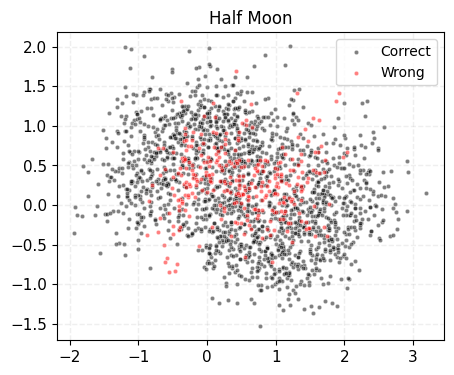

In [11]:
# Recycle the visualization scripts earlier
fig,ax = plt.subplots(1,1,figsize=(5,4))
##############################################################################################################################
# 1. Plot correct prediction here
##############################################################################################################################
# black --> correctly classified points
scatter_corr = ax.scatter(corr_X[:,0],corr_X[:,1],s=10,color='k',edgecolor='w',linewidths=0.5,alpha=0.5,label='Correct')
##############################################################################################################################
# 2. Plot wrong prediction here
##############################################################################################################################
# red --> misclassified points
scatter_wrong = ax.scatter(wrong_X[:,0],wrong_X[:,1],s=10,color='r',edgecolor='w',linewidths=0.5,alpha=0.5,label='Wrong')
##############################################################################################################################
# 3. Title etc.
##############################################################################################################################
ax.set_title('Half Moon')
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(alpha=0.2,ls='--',lw=1)
ax.legend()
plt.show()

Can you think of ways to improve your best model?

## Bonus Exercise 2: Upgrading the Decision Tree to a Random Forest

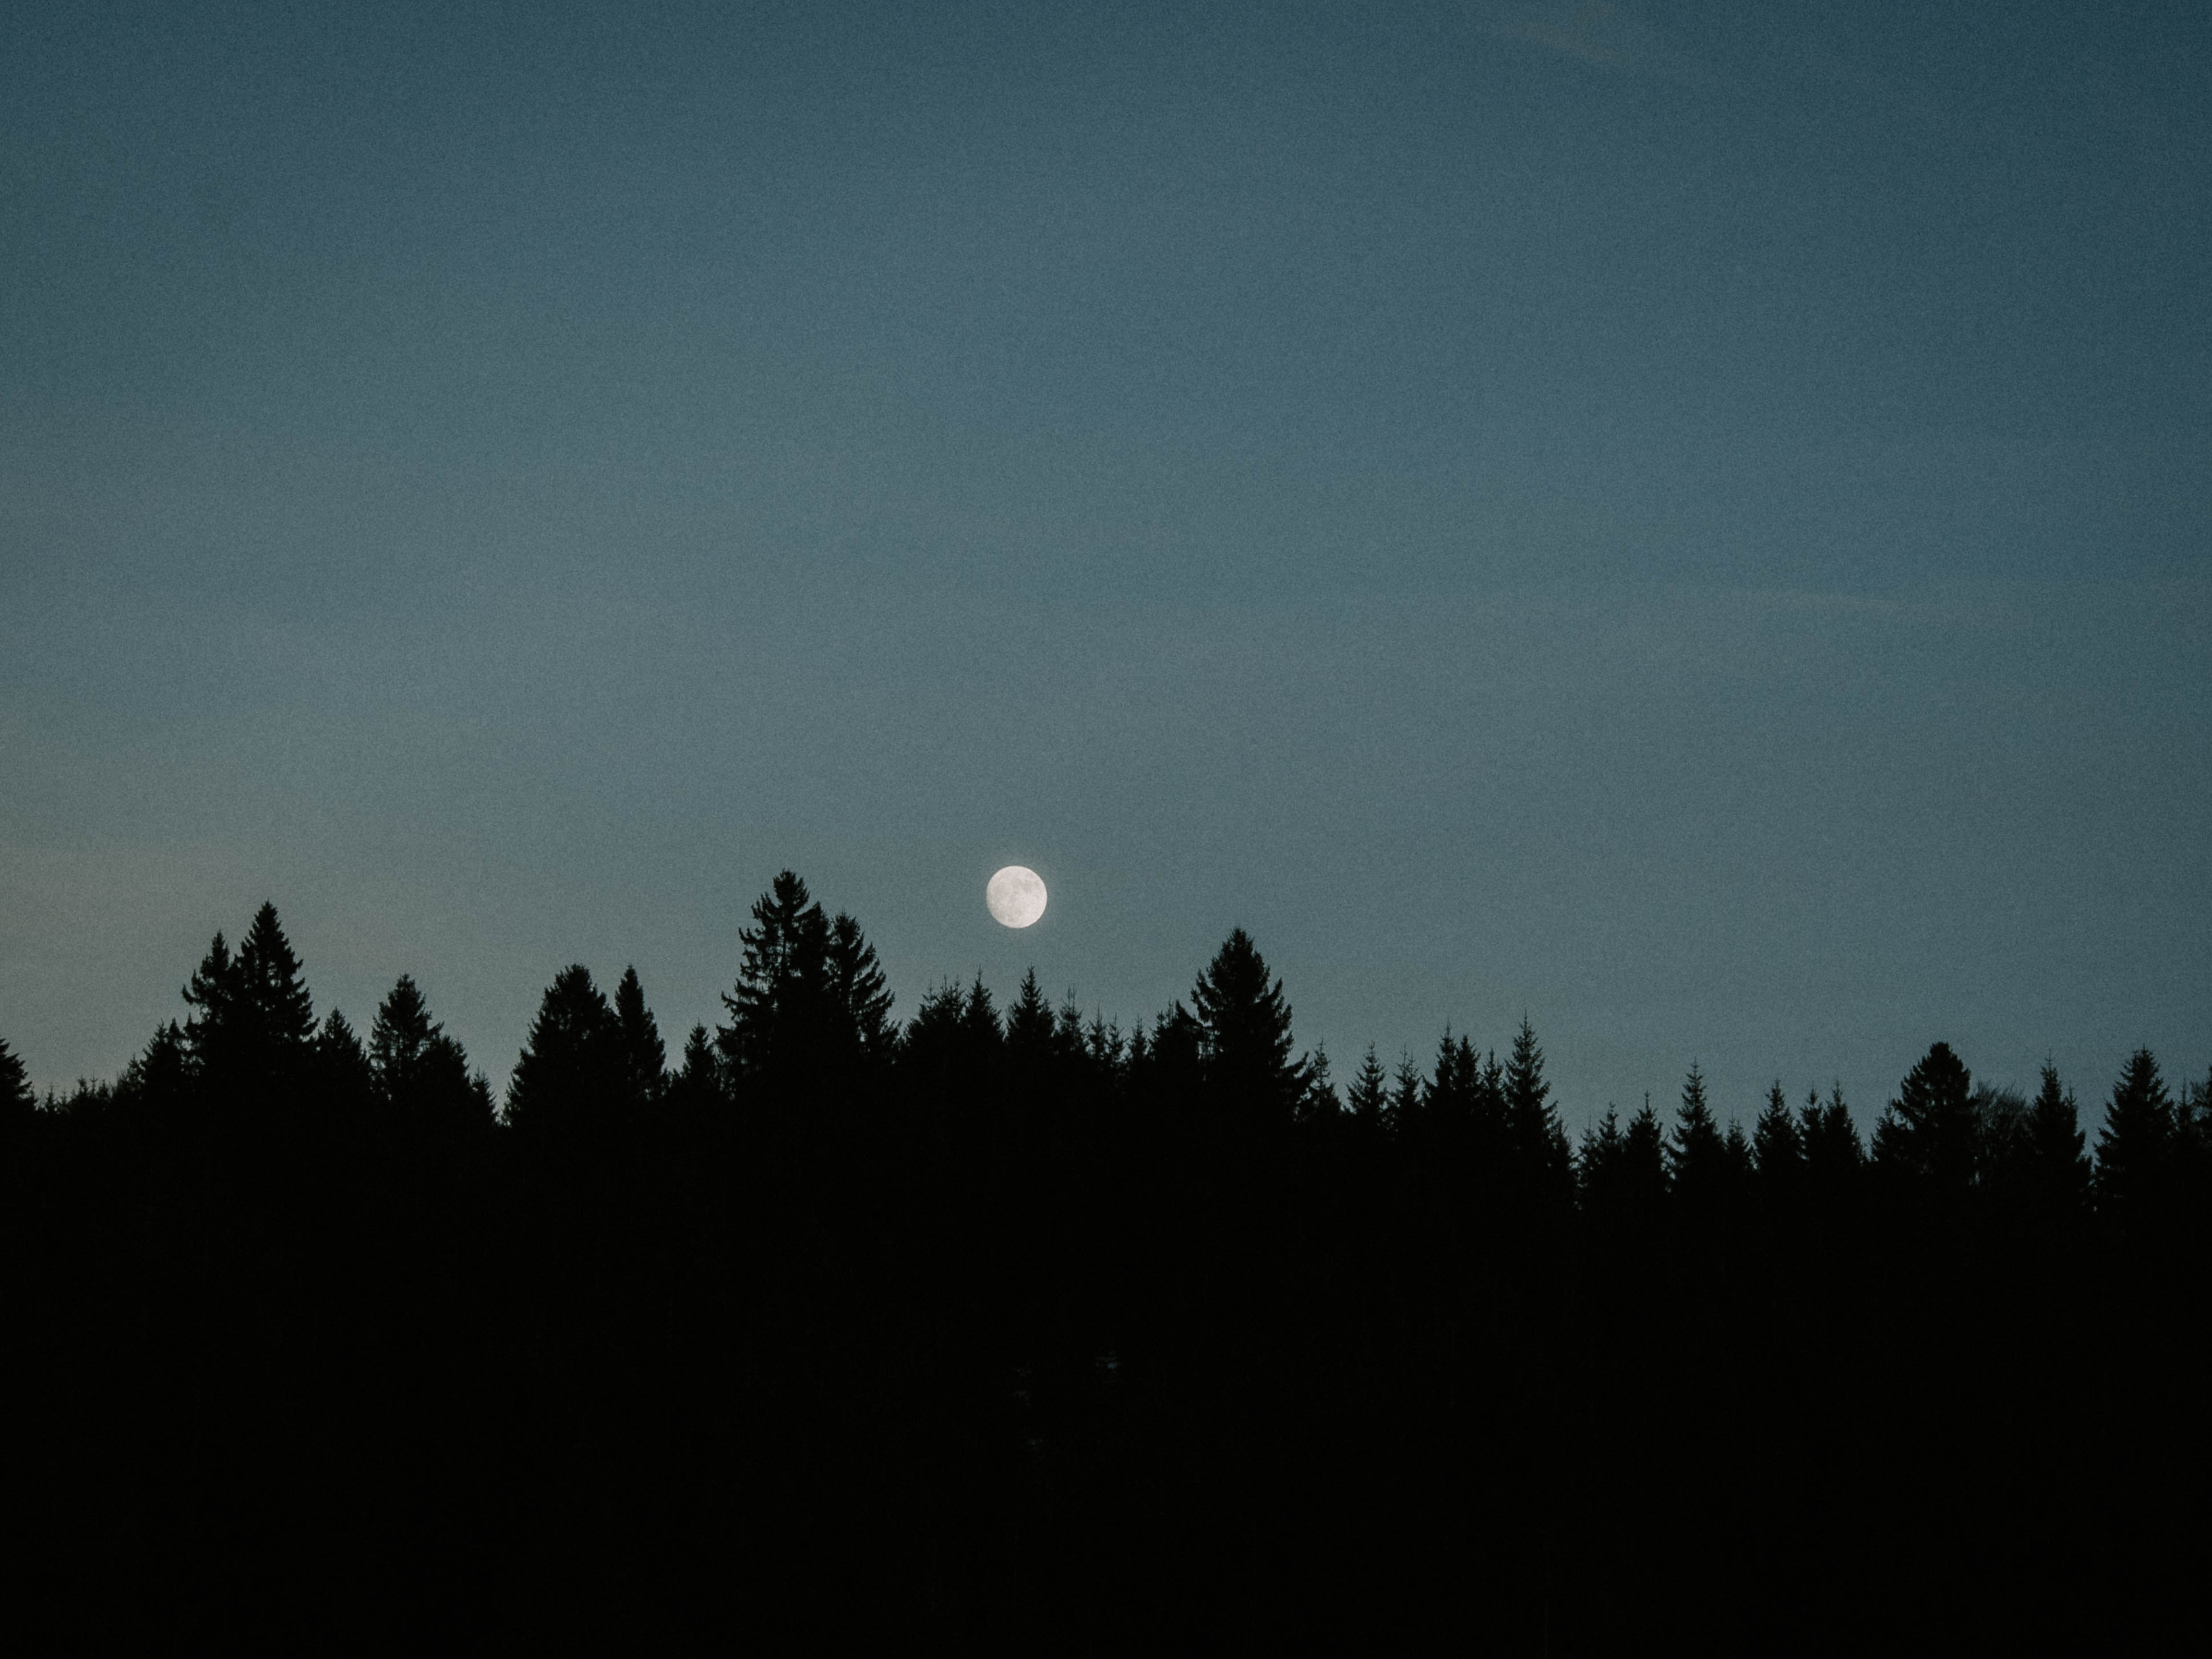

Is a full forest enough to predict the moon? 🌲

Building on the previous exercise, we would like to upgrade the decision tree to a random forest to make more accurate predictions on the `moons` dataset.

**Q1) Generate 1,000 subsets of the training set, each containing 100 instances selected randomly**

Hint: You may use `scikit-learn`'s random permutation cross-validator [ShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.ShuffleSplit.html) with the appropriate value of the  `n_splits` parameter.

In [12]:
# Import and build the random permutation cross-validator
from sklearn.model_selection import ShuffleSplit

# n_splits=1000 --> 1000 different random subsets
# train_size=100 --> each subset has only 100 training points | random_state --> reproducible
rs = ShuffleSplit(n_splits=1000, train_size=100, random_state=42)

In [13]:
# Generate 1,000 subsets of the training sets with
# 100 randomly-selected instances
# rs.split --> gives (train_indices, test_indices) for each split --> we only need the train ones
mini_sets = []
for mini_train_index, _ in rs.split(X_train):
    X_mini = X_train[mini_train_index]   # the 100 selected points
    y_mini = y_train[mini_train_index]   # and their labels
    mini_sets.append((X_mini, y_mini))

**Q2) Train one [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) on each subset, using the best hyperparameter values found [above](#Q3)**

In [14]:
# Train one decision tree per subset (clone also works! but here I'd like to do this the hard way =])
# Train one decision tree per subset (clone also works! but here I'd like to do this the hard way =])
# best_params_ --> dict with the best hyperparameters from the grid search
# ** --> unpacks the dict into keyword arguments (max_leaf_nodes=..., min_samples_split=...)
forest = [DecisionTreeClassifier(**gsc_tree.best_params_, random_state=42) for _ in range(1000)]

# zip --> pairs tree number i with subset number i
for tree, (X_mini, y_mini) in zip(forest, mini_sets):
    tree.fit(X_mini, y_mini)

**Q3) Evaluate each decision tree on the test set and visualize their accuracy**

Hint 1: You can quickly make histograms by using `Matplotlib.pyplot`'s [`hist`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html) function

Hint 2: The mean accuracy of your decision trees should be approximately 80% because the decision trees are fitted on smaller sets.

In [15]:
# Calculate the mean accuracy
# each tree --> predicts the WHOLE test set --> one accuracy per tree --> 1000 values
accuracy_scores = []
for tree in forest:
    y_pred_tree = tree.predict(X_test)
    accuracy_scores.append(accuracy_score(y_test, y_pred_tree))

# only 100 training points each --> worse trees than before --> ~80% on average
print(f'Mean accuracy of the single trees: {np.mean(accuracy_scores):.2%}')

Mean accuracy of the single trees: 79.15%


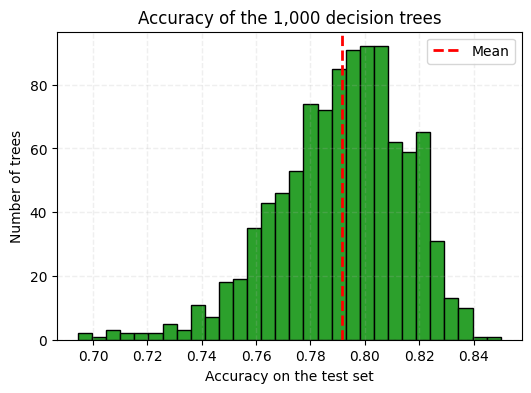

In [17]:
# Visualize the distribution of accuracies

# Visualize the distribution of accuracies
fig, ax = plt.subplots(figsize=(6,4))
# histogram --> how many trees fall in each accuracy range
ax.hist(accuracy_scores, bins=30, color='tab:green', edgecolor='k')
# vertical line at the mean --> easy reference
ax.axvline(np.mean(accuracy_scores), c='r', ls='--', lw=2, label='Mean')
ax.set_xlabel('Accuracy on the test set')
ax.set_ylabel('Number of trees')
ax.set_title('Accuracy of the 1,000 decision trees')
ax.legend()
ax.grid(alpha=0.2,ls='--',lw=1)
plt.show()

Now comes the magic ❇ 🌲 ❇

**Q4) Generate the predictions of the 1,000 decision trees over the test set, and only keep the most frequent prediction. This gives you *majority-vote predictions* over the test set**

Hint: You may use `Scipy`'s [`mode`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mode.html) function to calculate the most frequent prediction.

In [18]:
# Generate the predictions of all trained decision trees over the test set
# result --> matrix of shape (1000 trees, 2000 test points)
# each ROW = predictions of one tree, each COLUMN = the 1000 "votes" for one test point
Y_pred = np.array([tree.predict(X_test) for tree in forest])

In [19]:
# For each instance of the test set, calculate the majority-vote prediction
from scipy.stats import mode

# axis=0 --> most frequent value along the trees (down each column) --> one winning class per test point
# keepdims=False --> returns a flat array of shape (2000,) instead of (1, 2000)
y_pred_majority_votes, n_votes = mode(Y_pred, axis=0, keepdims=False)

Congratulations!! 😃 You have created a random forest classifier 🌲 🌳 🌲

**Q5) Calculate the accuracy of your random forest classifier and visualize its performance**

Hint: Your accuracy should be approximately 1% higher than your best decision tree.

In [20]:
# Calculate the accuracy of your random forest classifier
acc_forest = accuracy_score(y_test, y_pred_majority_votes)
print(f'Random forest accuracy: {acc_forest:.2%}')
# vs best single tree --> the vote cancels out part of the individual errors --> lower variance
print(f'Best decision tree accuracy: {accuracy_score(y_test, y_pred_test):.2%}')

Random forest accuracy: 85.80%
Best decision tree accuracy: 85.15%


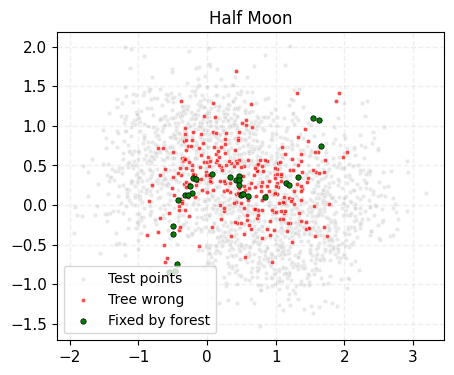

Points fixed by the forest: 29


In [21]:
# Visualize its errors: Which points did the
# random forest classify correctly
# when the decision tree was making an error?
# boolean masks --> True/False for every test point
tree_wrong = (y_pred_test != y_test)                  # the single best tree was wrong
forest_right = (y_pred_majority_votes == y_test)      # the forest got it right
fixed = tree_wrong & forest_right                     # both --> errors "fixed" by the forest

fig, ax = plt.subplots(1,1,figsize=(5,4))
# grey background --> all the test points
ax.scatter(X_test[:,0], X_test[:,1], s=10, color='lightgrey', edgecolor='w', linewidths=0.5, alpha=0.5, label='Test points')
# red --> tree wrong (whatever the forest did)
ax.scatter(X_test[tree_wrong,0], X_test[tree_wrong,1], s=10, color='r', edgecolor='w', linewidths=0.5, alpha=0.7, label='Tree wrong')
# green --> tree wrong BUT forest right --> where the majority vote helped
ax.scatter(X_test[fixed,0], X_test[fixed,1], s=15, color='g', edgecolor='k', linewidths=0.5, label='Fixed by forest')
ax.set_title('Half Moon')
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(alpha=0.2,ls='--',lw=1)
ax.legend()
plt.show()

print(f'Points fixed by the forest: {fixed.sum()}')